In [ ]:
 #Connecting to drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
#Import Libraries
import pandas as pd
import numpy as np

In [ ]:
#Load Dataset
df = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/paysim.csv', nrows=100000)

In [ ]:
#Basic Exploration
df.head()
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 11 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   step            100000 non-null  int64  
 1   type            100000 non-null  object 
 2   amount          100000 non-null  float64
 3   nameOrig        100000 non-null  object 
 4   oldbalanceOrg   100000 non-null  float64
 5   newbalanceOrig  100000 non-null  float64
 6   nameDest        100000 non-null  object 
 7   oldbalanceDest  100000 non-null  float64
 8   newbalanceDest  100000 non-null  float64
 9   isFraud         100000 non-null  int64  
 10  isFlaggedFraud  100000 non-null  int64  
dtypes: float64(5), int64(3), object(3)
memory usage: 8.4+ MB


In [ ]:
#Check Missing Values
df.isnull().sum()

,0
step,0
type,0
amount,0
nameOrig,0
oldbalanceOrg,0
newbalanceOrig,0
nameDest,0
oldbalanceDest,0
newbalanceDest,0
isFraud,0


In [ ]:
#Drop Unnecessary Columns
df = df.drop(['nameOrig', 'nameDest'], axis=1, errors='ignore')

In [ ]:
df = df.drop(['isFlaggedFraud'], axis=1)

In [ ]:
#Convert Categorical → Numerical
df = pd.get_dummies(df, columns=['type'], drop_first=True)

In [ ]:

df['isFraud'].value_counts()

,count
isFraud,
0,99884
1,116


In [ ]:
#Handle Imbalance
from sklearn.utils import resample

df_majority = df[df.isFraud == 0]
df_minority = df[df.isFraud == 1]

df_minority_upsampled = resample(df_minority,
                                replace=True,
                                n_samples=len(df_majority),
                                random_state=42)

df_balanced = pd.concat([df_majority, df_minority_upsampled])

In [ ]:
#Split Features & Target
X = df_balanced.drop('isFraud', axis=1)
y = df_balanced['isFraud']

In [ ]:
#Train-Test Split
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

In [ ]:
#Feature Scaling
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [ ]:
#Save Processed Data
df.to_csv('/content/drive/MyDrive/Colab Notebooks/paysim_processed.csv', index=False)

In [ ]:
#Import ML Libraries
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [ ]:
#Train Random Forest
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

In [ ]:
#Predict (Random Forest)
y_pred_rf = rf.predict(X_test)

In [ ]:
#Evaluate Random Forest
print("Random Forest Accuracy:", accuracy_score(y_test, y_pred_rf))
print("\nClassification Report:\n", classification_report(y_test, y_pred_rf))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred_rf))

Random Forest Accuracy: 0.9999249136506984

Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00     19954
           1       1.00      1.00      1.00     20000

    accuracy                           1.00     39954
   macro avg       1.00      1.00      1.00     39954
weighted avg       1.00      1.00      1.00     39954


Confusion Matrix:
 [[19951     3]
 [    0 20000]]


In [ ]:
#Train XGBoost
xgb = XGBClassifier(use_label_encoder=False, eval_metric='logloss')
xgb.fit(X_train, y_train)

/usr/local/lib/python3.12/dist-packages/xgboost/training.py:200: UserWarning: [14:11:49] WARNING: /__w/xgboost/xgboost/src/learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=None, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=None, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=None, n_jobs=None,
              num_parallel_tree=None, ...)

In [ ]:
#Predict (XGBoost)
y_pred_xgb = xgb.predict(X_test)

In [ ]:
#Evaluate XGBoost
print("XGBoost Accuracy:", accuracy_score(y_test, y_pred_xgb))
print("\nClassification Report:\n", classification_report(y_test, y_pred_xgb))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred_xgb))

XGBoost Accuracy: 0.9998247985182961

Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00     19954
           1       1.00      1.00      1.00     20000

    accuracy                           1.00     39954
   macro avg       1.00      1.00      1.00     39954
weighted avg       1.00      1.00      1.00     39954


Confusion Matrix:
 [[19947     7]
 [    0 20000]]


# Model Evaluation and Visualization

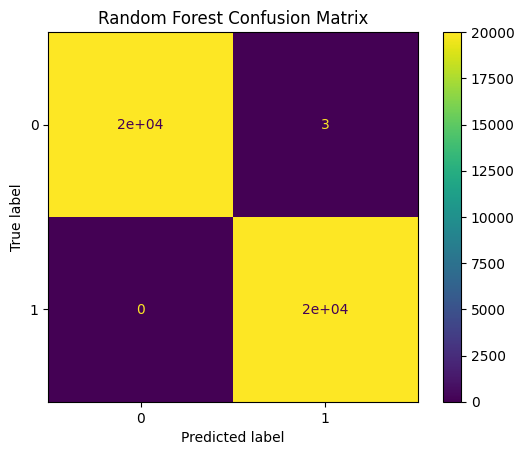

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_estimator(rf, X_test, y_test)
plt.title("Random Forest Confusion Matrix")
plt.show()

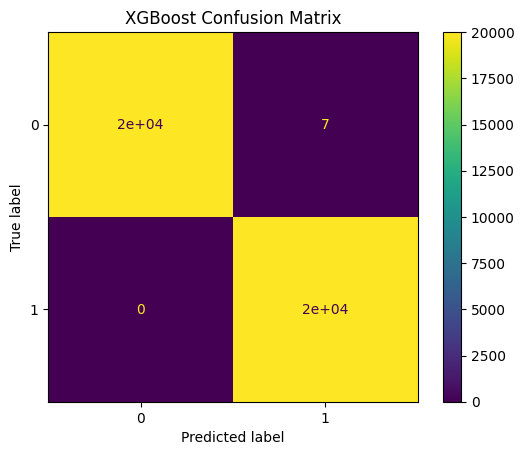

In [ ]:
ConfusionMatrixDisplay.from_estimator(xgb, X_test, y_test)
plt.title("XGBoost Confusion Matrix")
plt.show()

# Feature Importance Analysis


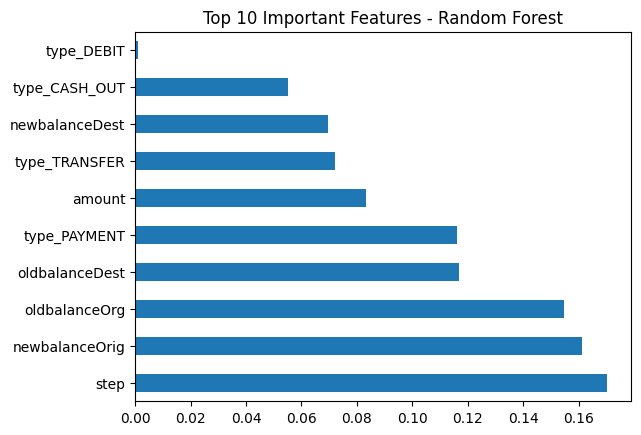

In [ ]:
import pandas as pd

importance = rf.feature_importances_
features = X.columns

feat_imp = pd.Series(importance, index=features)

feat_imp.nlargest(10).plot(kind='barh')

plt.title("Top 10 Important Features - Random Forest")

plt.show()

# Model Comparison


In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
comparison = pd.DataFrame({
    'Model': ['Random Forest', 'XGBoost'],
    'Accuracy': [
        accuracy_score(y_test, y_pred_rf),
        accuracy_score(y_test, y_pred_xgb)
    ],
    'Precision': [
        precision_score(y_test, y_pred_rf),
        precision_score(y_test, y_pred_xgb)
    ],
    'Recall': [
        recall_score(y_test, y_pred_rf),
        recall_score(y_test, y_pred_xgb)
    ],
    'F1-Score': [
        f1_score(y_test, y_pred_rf),
        f1_score(y_test, y_pred_xgb)
    ]
})
comparison

,Model,Accuracy,Precision,Recall,F1-Score
0,Random Forest,0.999925,0.99985,1.0,0.999925
1,XGBoost,0.999825,0.99965,1.0,0.999825


# Conclusion

The project successfully implemented a UPI fraud detection system using Random Forest and XGBoost algorithms. The models were trained using the PaySim dataset after preprocessing and handling class imbalance. Performance evaluation showed that both models effectively identified fraudulent transactions, with XGBoost providing slightly better prediction performance. The proposed system can help improve the security and reliability of digital payment systems by detecting suspicious transactions accurately.

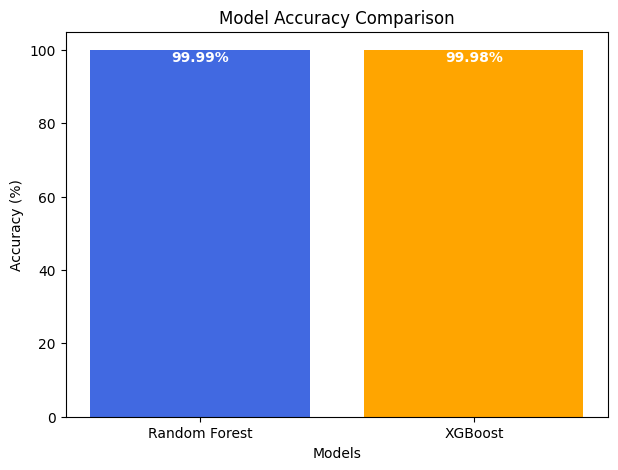

In [ ]:
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt

rf_accuracy = accuracy_score(y_test, y_pred_rf)
xgb_accuracy = accuracy_score(y_test, y_pred_xgb)

models = ['Random Forest', 'XGBoost']
accuracies = [rf_accuracy * 100, xgb_accuracy * 100]

plt.figure(figsize=(7,5))

bars = plt.bar(
    models,
    accuracies,
    color=['royalblue', 'orange']   # different colors
)

plt.title('Model Accuracy Comparison')
plt.xlabel('Models')
plt.ylabel('Accuracy (%)')

# Give some extra space above bars
plt.ylim(0, 105)

# Percentage labels
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2,
        height - 3,               # move label inside the bar
        f'{height:.2f}%',
        ha='center',
        color='white',
        fontweight='bold'
    )

plt.show()

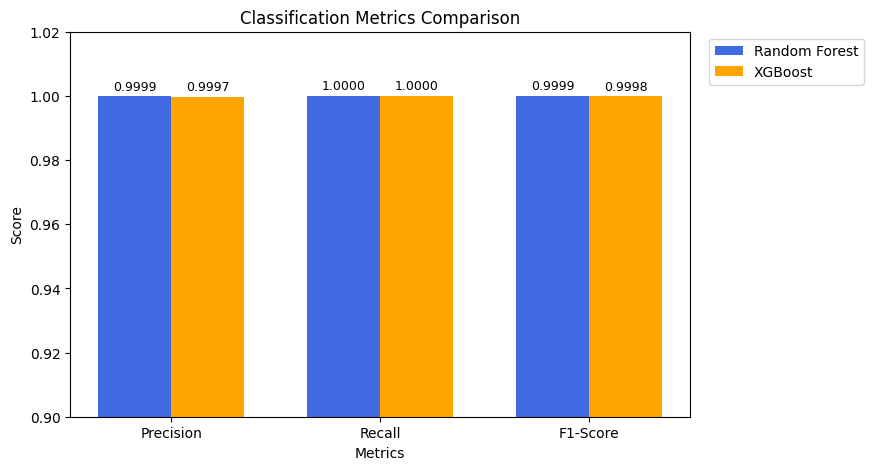

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

metrics = ['Precision', 'Recall', 'F1-Score']

rf_values = [rf_precision, rf_recall, rf_f1]
xgb_values = [xgb_precision, xgb_recall, xgb_f1]

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(8,5))

bars1 = plt.bar(
    x - width/2,
    rf_values,
    width,
    color='royalblue',
    label='Random Forest'
)

bars2 = plt.bar(
    x + width/2,
    xgb_values,
    width,
    color='orange',
    label='XGBoost'
)

plt.xticks(x, metrics)
plt.ylabel('Score')
plt.xlabel('Metrics')
plt.title('Classification Metrics Comparison')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')

# Value labels
for bar in bars1:
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 0.002,
        f'{bar.get_height():.4f}',
        ha='center',
        fontsize=9
    )

for bar in bars2:
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 0.002,
        f'{bar.get_height():.4f}',
        ha='center',
        fontsize=9
    )

plt.ylim(0.90, 1.02)
plt.show()

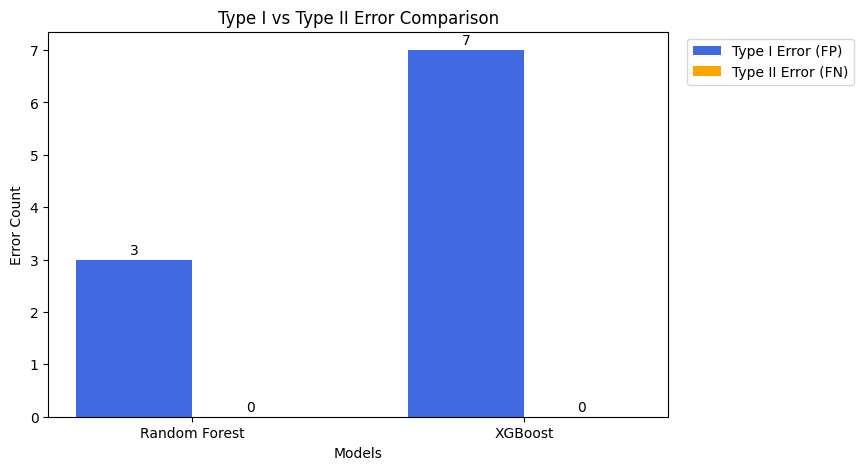

In [ ]:
from sklearn.metrics import confusion_matrix
import numpy as np
import matplotlib.pyplot as plt

# Confusion Matrices
cm_rf = confusion_matrix(y_test, y_pred_rf)
cm_xgb = confusion_matrix(y_test, y_pred_xgb)

# Extract TN, FP, FN, TP
tn_rf, fp_rf, fn_rf, tp_rf = cm_rf.ravel()
tn_xgb, fp_xgb, fn_xgb, tp_xgb = cm_xgb.ravel()

# Error values
type1_errors = [fp_rf, fp_xgb]   # False Positives
type2_errors = [fn_rf, fn_xgb]   # False Negatives

models = ['Random Forest', 'XGBoost']

x = np.arange(len(models))
width = 0.35

plt.figure(figsize=(8,5))

bars1 = plt.bar(
    x - width/2,
    type1_errors,
    width,
    color='royalblue',
    label='Type I Error (FP)'
)

bars2 = plt.bar(
    x + width/2,
    type2_errors,
    width,
    color='orange',
    label='Type II Error (FN)'
)

plt.xlabel('Models')
plt.ylabel('Error Count')
plt.title('Type I vs Type II Error Comparison')
plt.xticks(x, models)

# Show values on bars
for bar in bars1:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2,
        height + 0.1,
        str(int(height)),
        ha='center'
    )

for bar in bars2:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2,
        height + 0.1,
        str(int(height)),
        ha='center'
    )

plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc='upper left'
)

plt.show()